# NIH ChestX-ray14: Basic EDA and Conservative Label Cleaning

Run the notebook from top to bottom. It checks image inventory, metadata quality, patient IDs, image dimensions and quality, pixel distributions, exact Pneumonia/No Finding label eligibility, and official test-list membership.

> **Current files available:** a 10,000-image archive and an image inventory. The original NIH metadata CSV and `test_list.txt` are not currently present. Until you add those files below, no findings or official split membership will be inferred. All images will remain in the output with labels marked excluded/unavailable.

NIH labels are report-derived and are not perfect clinical ground truth. Unusual image dimensions or brightness are flagged for review, not automatically removed. The original metadata CSV is read-only in this workflow.

## 1. Imports and paths
Set `METADATA_CSV` and `OFFICIAL_TEST_LIST` if you have the NIH source files.

In [1]:
from pathlib import Path
from collections import Counter
import csv, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path('nih_chestxray14')
INVENTORY_CSV = ROOT / 'eda' / 'image_inventory.csv'
OUTPUT_DIR = ROOT / 'metadata'
EDA_DIR = ROOT / 'eda'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Update these paths when the original NIH files are available.
METADATA_CSV = None  # e.g. Path('nih_chestxray14/metadata/Data_Entry_2017.csv')
OFFICIAL_TEST_LIST = None  # e.g. Path('nih_chestxray14/metadata/test_list.txt')

assert INVENTORY_CSV.exists(), f'Image inventory not found: {INVENTORY_CSV}'
print('Image inventory:', INVENTORY_CSV.resolve())
print('Metadata CSV:', METADATA_CSV if METADATA_CSV else 'not supplied')
print('Official test list:', OFFICIAL_TEST_LIST if OFFICIAL_TEST_LIST else 'not supplied')

Image inventory: /Users/sakshammangla/Documents/NIH -DATASET/nih_chestxray14/eda/image_inventory.csv
Metadata CSV: not supplied
Official test list: not supplied


## 2. Load inventory and inspect dataset shape

In [2]:
inventory = pd.read_csv(INVENTORY_CSV)
print(f'Image inventory rows: {len(inventory):,}')
print(f'Inventory columns: {len(inventory.columns)}')
display(inventory.head())
display(pd.DataFrame({'dtype': inventory.dtypes.astype(str), 'missing': inventory.isna().sum(), 'unique': inventory.nunique(dropna=False)}))

Image inventory rows: 10,000
Inventory columns: 11


,image,bytes,width,height,mode,mean_intensity,std_intensity,min_intensity,max_intensity,sha256,duplicate_of
0,00008468_031.png,474636,1024,1024,L,107.811021,54.625442,0,255,4c3c7ce9201a1b7b2aca9287a786cc497e90eed0be5794...,NaN
1,00007408_001.png,361333,1024,1024,L,155.020240,63.643269,0,250,86641b786d09e2b8179b758ee28c6491257df4b3837e18...,NaN
2,00007747_001.png,360981,1024,1024,L,156.673311,51.843194,2,247,b649e70341be072188e367579f06332cea6a342a23f1a9...,NaN
3,00007245_002.png,351224,1024,1024,L,156.924585,39.736453,2,226,d6ff4050ffb472e14fafb0f855327c7e32699194b501ad...,NaN
4,00008151_001.png,395999,1024,1024,L,177.648625,52.037911,5,255,6242808507a6629d088fc6ac24dd9732d8e72a8c498c43...,NaN


,dtype,missing,unique
image,str,0,10000
bytes,int64,0,9564
width,int64,0,1
height,int64,0,1
mode,str,0,2
mean_intensity,float64,0,9995
std_intensity,float64,0,9996
min_intensity,int64,0,40
max_intensity,int64,0,79
sha256,str,0,10000


## 3. Metadata cleaning and reconciliation
The expected NIH columns are `Image Index`, `Patient ID`, and `Finding Labels`. Extra spaces around labels are trimmed. Duplicate filenames/records and files missing on either side are reported.

In [3]:
metadata = None
if METADATA_CSV is not None and Path(METADATA_CSV).exists():
    metadata = pd.read_csv(METADATA_CSV, dtype=str, keep_default_na=False)
    print('Loaded original metadata read-only:', METADATA_CSV)
else:
    print('Ground-truth metadata CSV is unavailable. Labels will remain unknown.')

if metadata is not None:
    required = ['Image Index', 'Patient ID', 'Finding Labels']
    missing_columns = [c for c in required if c not in metadata.columns]
    if missing_columns:
        raise ValueError(f'Metadata is missing required NIH columns: {missing_columns}')
    metadata['Image Index'] = metadata['Image Index'].str.strip()
    metadata['Patient ID'] = metadata['Patient ID'].str.strip()
    metadata['Finding Labels'] = metadata['Finding Labels'].map(lambda s: '|'.join(x.strip() for x in s.split('|') if x.strip()))
    metadata_quality = {
        'rows': int(len(metadata)),
        'missing_filenames': int(metadata['Image Index'].eq('').sum()),
        'missing_patient_ids': int(metadata['Patient ID'].eq('').sum()),
        'missing_findings': int(metadata['Finding Labels'].eq('').sum()),
        'duplicate_filenames': int(metadata['Image Index'].duplicated(keep=False).sum()),
        'duplicate_records': int(metadata.duplicated().sum()),
        'metadata_images_not_in_inventory': int((set(metadata['Image Index']) - set(inventory['image'])).__len__()),
        'inventory_images_without_metadata': int((set(inventory['image']) - set(metadata['Image Index'])).__len__()),
    }
    display(pd.Series(metadata_quality, name='count').to_frame())
else:
    metadata_quality = {'status': 'unavailable; no labels inferred'}

Ground-truth metadata CSV is unavailable. Labels will remain unknown.


## 4. Patient distribution and official split audit
Patient IDs are parsed from filename prefixes for grouping. The locally generated patient-level split is not a substitute for the official NIH test list. Do not randomly re-split the official test set.

In [4]:
inventory['patient_id'] = inventory['image'].astype(str).str.extract(r'^(\d+)_', expand=False)
patient_image_counts = inventory.groupby('patient_id', dropna=False).size().rename('image_count').sort_values(ascending=False)
display(patient_image_counts.describe().to_frame())
print('Unique filename-derived patient IDs:', inventory['patient_id'].nunique())
print('Missing/unparseable patient IDs:', int(inventory['patient_id'].isna().sum()))
patient_image_counts.to_csv(EDA_DIR / 'images_per_patient.csv', header=True)

official_test_images = None
if OFFICIAL_TEST_LIST is not None and Path(OFFICIAL_TEST_LIST).exists():
    official_test_images = {line.strip() for line in Path(OFFICIAL_TEST_LIST).read_text().splitlines() if line.strip()}
    inventory_names = set(inventory['image'])
    test_patients = {re.match(r'^(\d+)_', name).group(1) for name in official_test_images if re.match(r'^(\d+)_', name)}
    print('Official test filenames:', len(official_test_images))
    print('Official test files found in this inventory:', len(official_test_images & inventory_names))
    print('Official test files absent from this inventory:', len(official_test_images - inventory_names))
    print('Official test patient IDs:', len(test_patients))
else:
    print('Official test_list.txt unavailable: official test membership and leakage cannot be verified.')

,image_count
count,2648.000000
mean,3.776435
std,6.568394
min,1.000000
25%,1.000000
50%,1.000000
75%,4.000000
max,83.000000


Unique filename-derived patient IDs: 2648
Missing/unparseable patient IDs: 0
Official test_list.txt unavailable: official test membership and leakage cannot be verified.


## 5. Image dimensions, formats, and integrity flags
This uses the precomputed full-decode inventory. Dimension and brightness outliers are flagged for investigation; this notebook does not delete images.

In [5]:
inventory['width'] = pd.to_numeric(inventory['width'], errors='coerce')
inventory['height'] = pd.to_numeric(inventory['height'], errors='coerce')
for col in ['bytes', 'mean_intensity', 'std_intensity', 'min_intensity', 'max_intensity']:
    if col in inventory:
        inventory[col] = pd.to_numeric(inventory[col], errors='coerce')
print('Dimension counts:')
display(inventory.groupby(['width', 'height'], dropna=False).size().rename('images').to_frame())
print('Image modes:')
display(inventory['mode'].value_counts(dropna=False).rename('images').to_frame())

inventory['invalid_dimensions'] = inventory['width'].isna() | inventory['height'].isna() | inventory['width'].le(0) | inventory['height'].le(0)
inventory['blank_constant'] = inventory['min_intensity'].eq(inventory['max_intensity'])
inventory['low_contrast_flag'] = inventory['std_intensity'].lt(1)
inventory['duplicate_image'] = inventory['duplicate_of'].fillna('').ne('')
quality_counts = pd.Series({
    'invalid_or_zero_dimensions': int(inventory['invalid_dimensions'].sum()),
    'blank_constant_images': int(inventory['blank_constant'].sum()),
    'low_contrast_std_below_1': int(inventory['low_contrast_flag'].sum()),
    'exact_duplicate_images': int(inventory['duplicate_image'].sum()),
    'duplicate_filenames': int(inventory['image'].duplicated().sum()),
})
display(quality_counts.to_frame('count'))
print('Low-contrast threshold is a review flag only; no images are removed.')

Dimension counts:


,,images
width,height,
1024,1024,10000


Image modes:


,images
mode,
L,9931
RGBA,69


/var/folders/ln/f_snw00s7313bb6j4xr_jg300000gn/T/ipykernel_4711/3206668808.py:14: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  inventory['duplicate_image'] = inventory['duplicate_of'].fillna('').ne('')


,count
invalid_or_zero_dimensions,0
blank_constant_images,0
low_contrast_std_below_1,0
exact_duplicate_images,0
duplicate_filenames,0


Low-contrast threshold is a review flag only; no images are removed.


## 6. Pixel distributions and image quality review
Compare brightness and contrast across images. The threshold is diagnostic only; investigate flagged images before making any cleaning decision.

,count,mean,std,min,25%,50%,75%,max
mean_intensity,10000.0,145.225359,22.715938,37.068234,128.401233,152.344091,162.038040,219.511774
std_intensity,10000.0,56.336071,10.263843,5.116926,48.843964,56.183301,64.055199,95.077578
bytes,10000.0,383726.739800,41404.817202,135295.000000,359225.750000,382067.500000,400927.000000,789842.000000


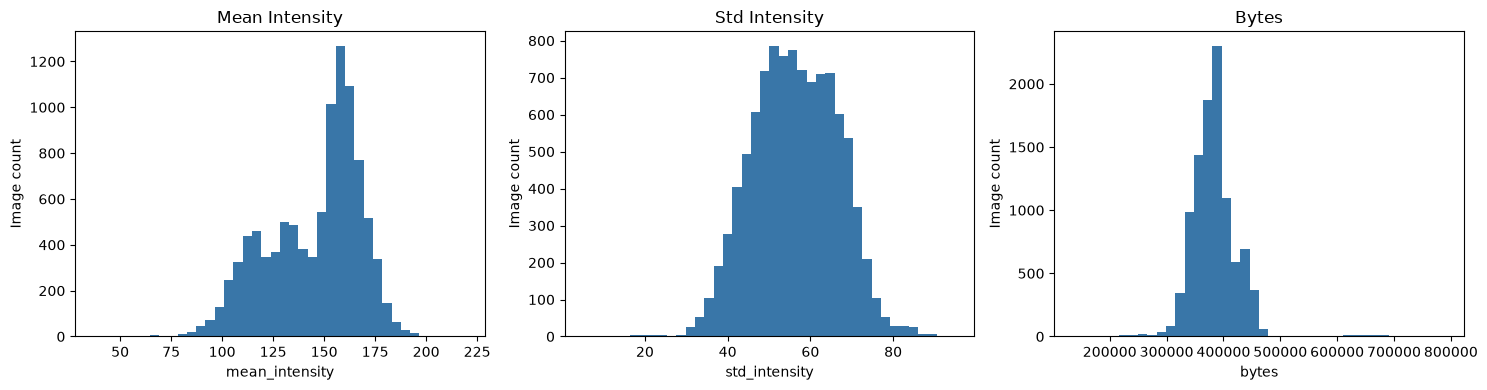

,image,patient_id,width,height,mean_intensity,std_intensity


In [6]:
pixel_columns = [c for c in ['mean_intensity', 'std_intensity', 'bytes'] if c in inventory]
display(inventory[pixel_columns].describe().T)
fig, axes = plt.subplots(1, len(pixel_columns), figsize=(5 * len(pixel_columns), 4))
axes = np.atleast_1d(axes)
for ax, col in zip(axes, pixel_columns):
    inventory[col].dropna().plot(kind='hist', bins=40, ax=ax, color='#3976a8', title=col.replace('_', ' ').title())
    ax.set_xlabel(col)
    ax.set_ylabel('Image count')
fig.tight_layout()
fig.savefig(EDA_DIR / 'basic_pixel_distributions.png', dpi=160)
plt.show()

# Review lowest-contrast and unusual-dimension cases, if any.
review = inventory[inventory['low_contrast_flag'] | inventory['invalid_dimensions']].copy()
display(review[['image', 'patient_id', 'width', 'height', 'mean_intensity', 'std_intensity']].head(20))

## 7. Exact binary label rules
Eligible positives have the complete annotation `Pneumonia`. Eligible negatives have the complete annotation `No Finding`. Pneumonia with other findings, other diseases, missing labels, and ambiguous annotations are excluded. An `Effusion` only case is not treated as a confirmed negative.

In [7]:
if metadata is not None:
    # Keep first row for each filename after reporting duplicates above.
    metadata_by_image = metadata.drop_duplicates('Image Index', keep='first').set_index('Image Index')
else:
    metadata_by_image = pd.DataFrame(columns=['Patient ID', 'Finding Labels'])
    metadata_by_image.index.name = 'Image Index'

labels = inventory[['image', 'patient_id']].copy().rename(columns={'image': 'image'})
labels['original_findings'] = labels['image'].map(metadata_by_image['Finding Labels'] if 'Finding Labels' in metadata_by_image else {}).fillna('')
labels['metadata_patient_id'] = labels['image'].map(metadata_by_image['Patient ID'] if 'Patient ID' in metadata_by_image else {}).fillna('')
labels['patient_id'] = labels['patient_id'].fillna(labels['metadata_patient_id'])
labels = labels.drop(columns='metadata_patient_id')
labels['binary_label'] = pd.NA
labels['class_name'] = 'EXCLUDED'
labels['eligible'] = False
labels['exclusion_reason'] = 'Ground-truth finding unavailable'
positive = labels['original_findings'].eq('Pneumonia')
negative = labels['original_findings'].eq('No Finding')
other = labels['original_findings'].ne('') & ~(positive | negative)
labels.loc[positive, ['binary_label', 'class_name', 'eligible', 'exclusion_reason']] = [1, 'PNEUMONIA', True, '']
labels.loc[negative, ['binary_label', 'class_name', 'eligible', 'exclusion_reason']] = [0, 'NORMAL', True, '']
labels.loc[other, 'exclusion_reason'] = 'Not an exact single-label Pneumonia or No Finding annotation'

if official_test_images is None:
    labels['official_test_split'] = 'unknown'
else:
    labels['official_test_split'] = np.where(labels['image'].isin(official_test_images), 'test', 'not_test')

label_path = OUTPUT_DIR / 'image_labels.csv'
labels.to_csv(label_path, index=False)
print('Saved:', label_path.resolve())
display(labels.head())
display(labels['class_name'].value_counts(dropna=False).rename('images').to_frame())
print('Eligible positives:', int(positive.sum()))
print('Eligible negatives:', int(negative.sum()))
print('Excluded:', int((~labels['eligible']).sum()))

Saved: /Users/sakshammangla/Documents/NIH -DATASET/nih_chestxray14/metadata/image_labels.csv


/var/folders/ln/f_snw00s7313bb6j4xr_jg300000gn/T/ipykernel_4711/1968990659.py:9: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  labels['original_findings'] = labels['image'].map(metadata_by_image['Finding Labels'] if 'Finding Labels' in metadata_by_image else {}).fillna('')
/var/folders/ln/f_snw00s7313bb6j4xr_jg300000gn/T/ipykernel_4711/1968990659.py:10: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  labels['metadata_patient_id'] = labels['image'].map(metadata_by_image['Patient ID'] if 'Patient ID' in metadata_by_image else {}).fillna('')


,image,patient_id,original_findings,binary_label,class_name,eligible,exclusion_reason,official_test_split
0,00008468_031.png,00008468,,<NA>,EXCLUDED,False,Ground-truth finding unavailable,unknown
1,00007408_001.png,00007408,,<NA>,EXCLUDED,False,Ground-truth finding unavailable,unknown
2,00007747_001.png,00007747,,<NA>,EXCLUDED,False,Ground-truth finding unavailable,unknown
3,00007245_002.png,00007245,,<NA>,EXCLUDED,False,Ground-truth finding unavailable,unknown
4,00008151_001.png,00008151,,<NA>,EXCLUDED,False,Ground-truth finding unavailable,unknown


,images
class_name,
EXCLUDED,10000


Eligible positives: 0
Eligible negatives: 0
Excluded: 10000


## 8. Save the EDA summary
This JSON summarizes available checks and documents missing inputs. It does not replace or overwrite the original NIH metadata CSV.

In [8]:
summary = {
    'inventory_csv': str(INVENTORY_CSV),
    'image_count': int(len(inventory)),
    'inventory_columns': list(inventory.columns),
    'metadata_csv': str(METADATA_CSV) if METADATA_CSV else None,
    'metadata_quality': metadata_quality,
    'unique_patient_ids_from_filename': int(inventory['patient_id'].nunique()),
    'images_per_patient': {k: float(v) for k, v in patient_image_counts.describe().to_dict().items()},
    'dimensions': {f'{w}x{h}': int(n) for (w, h), n in inventory.groupby(['width', 'height'], dropna=False).size().items()},
    'image_modes': {str(k): int(v) for k, v in inventory['mode'].value_counts(dropna=False).items()},
    'quality_flags': {k: int(v) for k, v in quality_counts.items()},
    'label_distribution': {str(k): int(v) for k, v in labels['class_name'].value_counts(dropna=False).items()},
    'official_test_list': str(OFFICIAL_TEST_LIST) if OFFICIAL_TEST_LIST else None,
    'official_test_membership': 'unknown' if official_test_images is None else 'reconciled by filename',
    'notes': ['No label or split membership is inferred when source files are absent.', 'Unusual images are flagged for review, not automatically removed.', 'NIH labels are report-derived, not clinical ground truth.']
}
summary_path = EDA_DIR / 'basic_eda_summary.json'
summary_path.write_text(json.dumps(summary, indent=2) + '\n', encoding='utf-8')
print('Saved:', summary_path.resolve())
print(json.dumps(summary, indent=2))

Saved: /Users/sakshammangla/Documents/NIH -DATASET/nih_chestxray14/eda/basic_eda_summary.json
{
  "inventory_csv": "nih_chestxray14/eda/image_inventory.csv",
  "image_count": 10000,
  "inventory_columns": [
    "image",
    "bytes",
    "width",
    "height",
    "mode",
    "mean_intensity",
    "std_intensity",
    "min_intensity",
    "max_intensity",
    "sha256",
    "duplicate_of",
    "patient_id",
    "invalid_dimensions",
    "blank_constant",
    "low_contrast_flag",
    "duplicate_image"
  ],
  "metadata_csv": null,
  "metadata_quality": {
    "status": "unavailable; no labels inferred"
  },
  "unique_patient_ids_from_filename": 2648,
  "images_per_patient": {
    "count": 2648.0,
    "mean": 3.7764350453172204,
    "std": 6.568394334657457,
    "min": 1.0,
    "25%": 1.0,
    "50%": 1.0,
    "75%": 4.0,
    "max": 83.0
  },
  "dimensions": {
    "1024x1024": 10000
  },
  "image_modes": {
    "L": 9931,
    "RGBA": 69
  },
  "quality_flags": {
    "invalid_or_zero_dimensions